<a href="https://colab.research.google.com/github/jenish14433-sketch/nlp-course/blob/main/African_News_Classifier_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q datasets scikit-learn sentence-transformers gradio joblib seaborn matplotlib pandas numpy pyarrow

## 2. Imports and reproducibility

We fix random seeds where possible so that sampling and model training are repeatable.

In [3]:
import os, json, random, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, f1_score
)
from sklearn.preprocessing import LabelEncoder
import joblib
import torch
from sentence_transformers import SentenceTransformer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path("/content/african_news_classifier")
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


## 3. Dataset source and language configurations

MasakhaNEWS provides train, validation and test splits for 16 African languages. The seven topic labels are business, entertainment, health, politics, religion, sports and technology. The current Hugging Face dataset card documents the article fields and language configurations.

Dataset card and licence: [Hugging Face — MasakhaNEWS](https://huggingface.co/datasets/masakhane/masakhanews). Check the licence terms before redistributing data or using this work commercially.

In [4]:
LANGUAGES = {
    "amh": "Amharic",
    "eng": "English",
    "fra": "French",
    "hau": "Hausa",
    "ibo": "Igbo",
    "lin": "Lingala",
    "lug": "Luganda",
    "orm": "Oromo",
    "pcm": "Nigerian Pidgin",
    "run": "Rundi",
    "sna": "chiShona",
    "som": "Somali",
    "swa": "Kiswahili",
    "tir": "Tigrinya",
    "xho": "isiXhosa",
    "yor": "Yoruba",
}

TOPICS = [
    "business", "entertainment", "health", "politics",
    "religion", "sports", "technology"
]
print(f"Language configurations: {len(LANGUAGES)}")
print("Topics:", TOPICS)

Language configurations: 16
Topics: ['business', 'entertainment', 'health', 'politics', 'religion', 'sports', 'technology']


## 4. Download and combine all 16 language datasets

The dataset is downloaded by language configuration. We use `headline` and `text` as the input, combine them into one text field, and keep the official split. The notebook handles either a text `category` field or an integer `label` field in case the dataset representation changes.

In [5]:
def standardize_split(frame, language_code, split_name):
    frame = frame.copy()

    # Current dataset card exposes category; some versions may expose label.
    if "category" in frame.columns:
        labels = frame["category"].astype(str)
    elif "label" in frame.columns:
        labels = frame["label"]
        # Older dataset versions may store topic IDs (0–6) rather than topic names.
        if pd.api.types.is_numeric_dtype(labels):
            labels = labels.map({i: topic for i, topic in enumerate(TOPICS)})
        else:
            labels = labels.astype(str)
    else:
        raise ValueError(f"No category/label column found. Columns: {list(frame.columns)}")

    headline = frame["headline"].fillna("").astype(str) if "headline" in frame else ""
    body = frame["text"].fillna("").astype(str) if "text" in frame else ""

    # Prefer headline + body rather than relying on a precomputed field.
    combined = (headline + " " + body).str.replace(r"\s+", " ", regex=True).str.strip()

    out = pd.DataFrame({
        "text": combined,
        "category": labels.str.lower().str.strip(),
        "language": language_code,
        "split": split_name
    })
    out = out[out["text"].str.len() > 0].copy()
    out = out[out["category"].isin(TOPICS)].copy()
    return out.reset_index(drop=True)


all_splits = {"train": [], "validation": [], "test": []}
load_errors = []

for code, language_name in LANGUAGES.items():
    print(f"Loading {language_name} ({code}) ...")
    try:
        ds = load_dataset("masakhane/masakhanews", code)
        for split_name in ["train", "validation", "test"]:
            split_df = ds[split_name].to_pandas()
            cleaned = standardize_split(split_df, code, split_name)
            all_splits[split_name].append(cleaned)
            print(f"  {split_name}: {len(cleaned):,} rows")
    except Exception as e:
        load_errors.append((code, str(e)))
        print(f"  ERROR loading {code}: {e}")

if load_errors:
    print("\nWARNING: Some language configurations did not load:")
    for code, error in load_errors:
        print(code, error[:300])
    raise RuntimeError("Not all 16 languages loaded. Fix the download issue and rerun this cell.")

train_df = pd.concat(all_splits["train"], ignore_index=True)
val_df = pd.concat(all_splits["validation"], ignore_index=True)
test_df = pd.concat(all_splits["test"], ignore_index=True)

# Remove exact duplicate text inside each split. We preserve official split membership.
train_df = train_df.drop_duplicates(subset=["text"]).reset_index(drop=True)
val_df = val_df.drop_duplicates(subset=["text"]).reset_index(drop=True)
test_df = test_df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("\nCombined split sizes")
display(pd.DataFrame({
    "split": ["train", "validation", "test"],
    "articles": [len(train_df), len(val_df), len(test_df)]
}))
print("Languages in train:", train_df["language"].nunique())
print("Unique topics:", sorted(train_df["category"].unique()))

Loading Amharic (amh) ...


README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

train.tsv:   0%|          | 0.00/7.33M [00:00<?, ?B/s]

dev.tsv:   0%|          | 0.00/936k [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1311 [00:00<?, ? examples/s]

... (106 outputs left out)

Generating test split:   0%|          | 0/411 [00:00<?, ? examples/s]

  train: 1,433 rows
  validation: 206 rows
  test: 411 rows

Combined split sizes


,split,articles
0,train,21600
1,validation,3108
2,test,6236


Languages in train: 16
Unique topics: ['business', 'entertainment', 'health', 'politics', 'religion', 'sports', 'technology']


## 5. Explore the real data

We inspect class balance, language representation, text lengths and sample articles. These checks help explain possible dataset bias and limitations.

In [6]:
display(train_df.head(5))

,text,category,language,split
0,የስፖርት ኮከቦች እና የንግድ ምልክቶቻቸው- ከቦልት እስከ ክርስቲያኖ ሮና...,sports,amh,train
1,እግር ኳስ፡ ዩናይትድ፣ አርሴናል፣ ቼልሲ . . . ምን አስበዋል? የስፖር...,sports,amh,train
2,ዓለምን ካስጨነቃት የዋጋ ንረት ተጠቃሚዎቹ እነማን ናቸው? ከኮሮናቫይረስ ...,business,amh,train
3,ኮሮናቫይረስ፡ በቫይረሱ የሞቱት የሮማኒያው ከንቲባ በምርጫ አሸነፉ በኮሮና...,health,amh,train
4,ኮሮናቫይረስ፡ አውሮፕላኖች እንዴት ነው በፀረ- ተህዋሲያን የሚፀዱት? የኮ...,health,amh,train


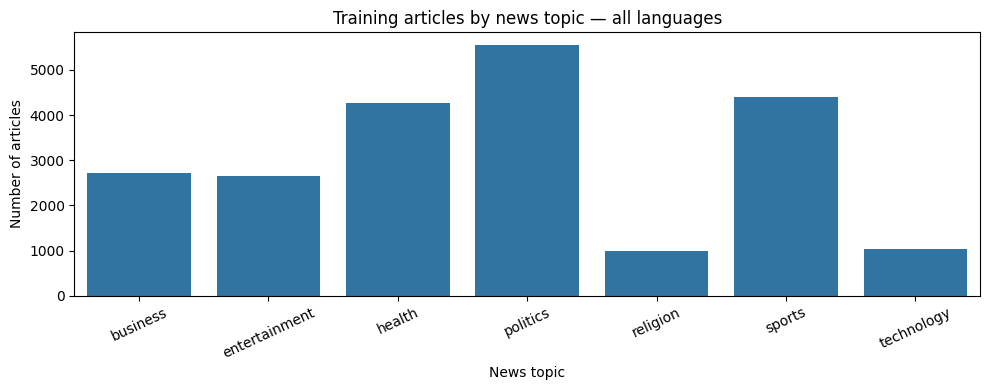

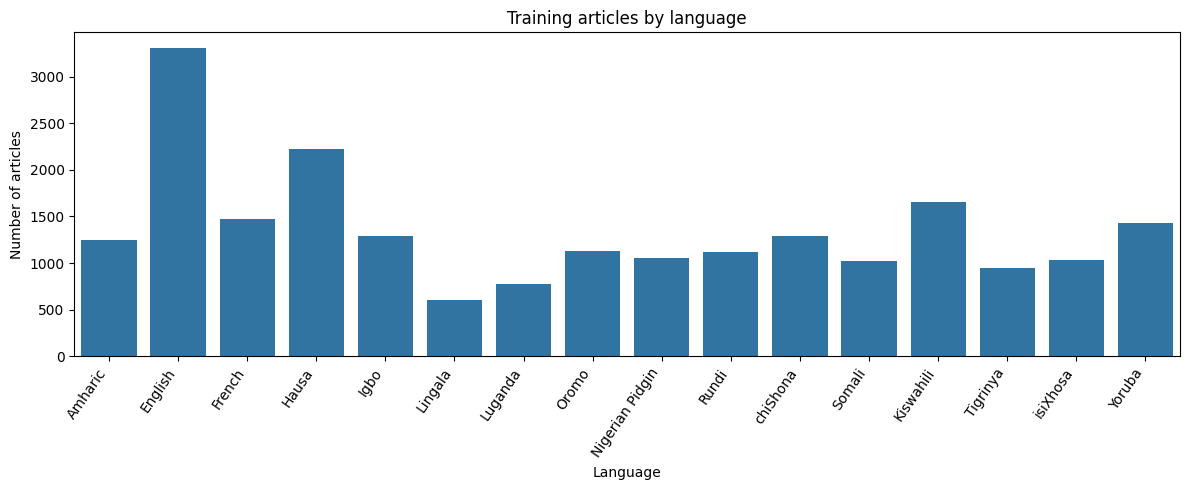

In [7]:
# Topic distribution across all training languages
topic_counts = train_df["category"].value_counts().reindex(TOPICS, fill_value=0)
plt.figure(figsize=(10, 4))
sns.barplot(x=topic_counts.index, y=topic_counts.values)
plt.title("Training articles by news topic — all languages")
plt.xlabel("News topic")
plt.ylabel("Number of articles")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Language distribution
language_counts = train_df["language"].value_counts().reindex(LANGUAGES.keys(), fill_value=0)
plt.figure(figsize=(12, 5))
sns.barplot(x=[LANGUAGES[x] for x in language_counts.index], y=language_counts.values)
plt.title("Training articles by language")
plt.xlabel("Language")
plt.ylabel("Number of articles")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

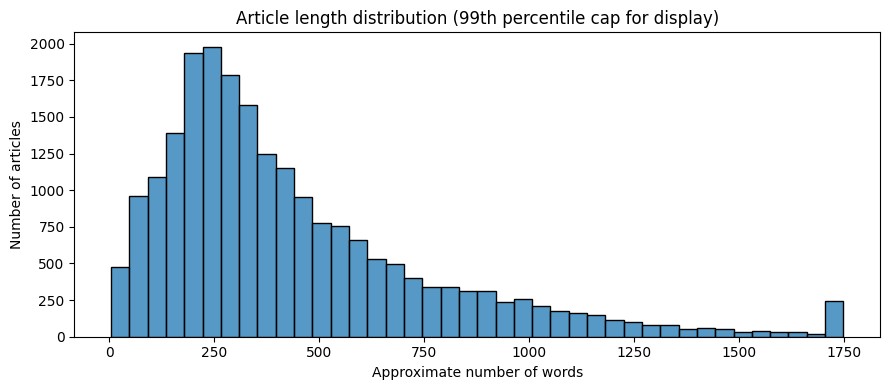

Median words: 342.0
95th percentile words: 1140.0499999999993
Empty texts: 0


In [8]:
train_df["word_count"] = train_df["text"].str.split().str.len()
plt.figure(figsize=(9, 4))
sns.histplot(train_df["word_count"].clip(upper=train_df["word_count"].quantile(0.99)), bins=40)
plt.title("Article length distribution (99th percentile cap for display)")
plt.xlabel("Approximate number of words")
plt.ylabel("Number of articles")
plt.tight_layout()
plt.show()

print("Median words:", train_df["word_count"].median())
print("95th percentile words:", train_df["word_count"].quantile(0.95))
print("Empty texts:", (train_df["text"].str.strip() == "").sum())

## 6. Prepare labels and text

The target is the seven-way news category. We use the official train and validation splits for model development and reserve the official test split for the final comparison.

In [9]:
label_encoder = LabelEncoder()
label_encoder.fit(TOPICS)

X_train = train_df["text"].tolist()
y_train = label_encoder.transform(train_df["category"])

X_val = val_df["text"].tolist()
y_val = label_encoder.transform(val_df["category"])

X_test = test_df["text"].tolist()
y_test = label_encoder.transform(test_df["category"])

label_names = list(label_encoder.classes_)
print("Label mapping:", {i: name for i, name in enumerate(label_names)})
print("Train / validation / test:", len(X_train), len(X_val), len(X_test))

Label mapping: {0: np.str_('business'), 1: np.str_('entertainment'), 2: np.str_('health'), 3: np.str_('politics'), 4: np.str_('religion'), 5: np.str_('sports'), 6: np.str_('technology')}
Train / validation / test: 21600 3108 6236


## 7. Model A — TF-IDF + Logistic Regression

TF-IDF represents text using word and character n-grams. Logistic Regression learns to associate these features with the seven news topics. Character n-grams can help with spelling variation and morphology, although they do not fully solve multilingual differences.

In [10]:
tfidf_model = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=2,
            max_features=150000,
            sublinear_tf=True
        )),
        ("char", TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            min_df=2,
            max_features=150000,
            sublinear_tf=True
        ))
    ])),
    ("classifier", LogisticRegression(
        max_iter=1200,
        class_weight="balanced",
        C=2.0,
        random_state=SEED
    ))
])

print("Training TF-IDF model...")
tfidf_model.fit(X_train, y_train)

tfidf_val_pred = tfidf_model.predict(X_val)
print("Validation macro-F1:", round(f1_score(y_val, tfidf_val_pred, average="macro"), 4))

Training TF-IDF model...
Validation macro-F1: 0.8518


## 8. Model B — Multilingual sentence embeddings + Logistic Regression

A pretrained multilingual sentence-transformer converts each article into a dense numeric vector. Logistic Regression then predicts the topic from those vectors. The encoder is `paraphrase-multilingual-MiniLM-L12-v2`.

**Important limitation:** multilingual does not mean equal performance in every language. We will inspect performance by language instead of assuming that the model works equally well for all 16.

In [12]:
EMBEDDING_MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

device = "cuda" if torch.cuda.is_available() else "cpu"
encoder = SentenceTransformer(EMBEDDING_MODEL_NAME, device=device)

def encode_texts(texts, batch_size=64):
    return encoder.encode(
        texts,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

print("Encoding training articles...")
train_embeddings = encode_texts(X_train)
print("Encoding validation articles...")
val_embeddings = encode_texts(X_val)

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Encoding training articles...


Batches:   0%|          | 0/338 [00:00<?, ?it/s]

Encoding validation articles...


Batches:   0%|          | 0/49 [00:00<?, ?it/s]

In [13]:
embedding_model = LogisticRegression(
    max_iter=1500,
    class_weight="balanced",
    C=2.0,
    random_state=SEED
)
print("Training embedding classifier...")
embedding_model.fit(train_embeddings, y_train)

embedding_val_pred = embedding_model.predict(val_embeddings)
print("Embedding model validation macro-F1:",
      round(f1_score(y_val, embedding_val_pred, average="macro"), 4))

Training embedding classifier...
Embedding model validation macro-F1: 0.65


## 9. Final test evaluation — compare both approaches

We now evaluate both models on the untouched official test split. The metrics include accuracy, macro precision, macro recall, macro-F1 and weighted-F1. Macro-F1 gives equal weight to each category and is useful when class sizes differ.

In [14]:
print("Encoding test articles...")
test_embeddings = encode_texts(X_test)

tfidf_test_pred = tfidf_model.predict(X_test)
embedding_test_pred = embedding_model.predict(test_embeddings)

def calculate_metrics(y_true, y_pred, model_name):
    p, r, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    _, _, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1_macro,
        "weighted_f1": f1_weighted
    }

comparison = pd.DataFrame([
    calculate_metrics(y_test, tfidf_test_pred, "TF-IDF + Logistic Regression"),
    calculate_metrics(y_test, embedding_test_pred, "Multilingual embeddings + Logistic Regression")
])
display(comparison.round(4))

Encoding test articles...


Batches:   0%|          | 0/98 [00:00<?, ?it/s]

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,TF-IDF + Logistic Regression,0.8818,0.8547,0.8665,0.8601,0.8825
1,Multilingual embeddings + Logistic Regression,0.6791,0.6300,0.6801,0.6418,0.6868


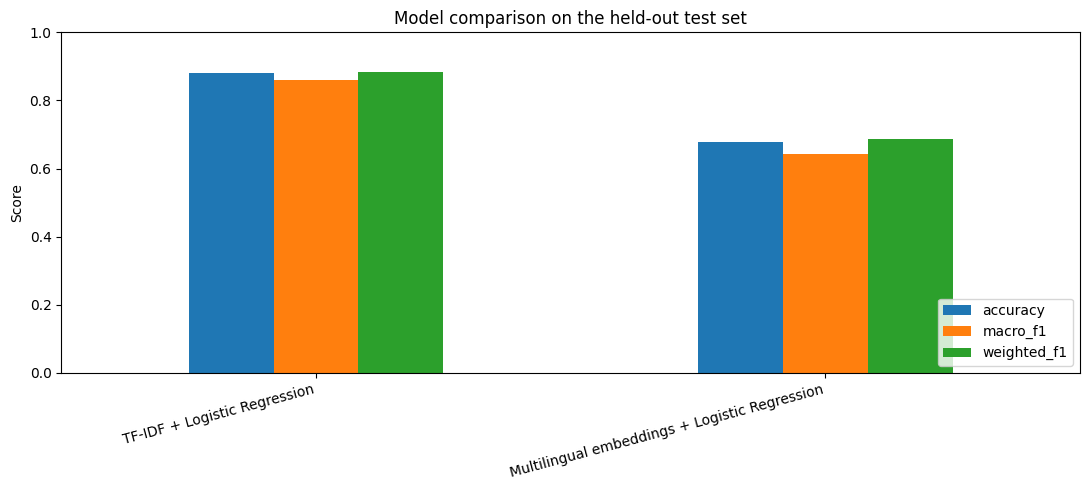

Best model by test macro-F1 (descriptive final comparison): TF-IDF + Logistic Regression


In [15]:
ax = comparison.set_index("model")[["accuracy", "macro_f1", "weighted_f1"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1)
)
ax.set_title("Model comparison on the held-out test set")
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_model_name = comparison.sort_values("macro_f1", ascending=False).iloc[0]["model"]
print("Best model by test macro-F1 (descriptive final comparison):", best_model_name)

## 10. Classification reports and confusion matrices

A confusion matrix shows which topics the model confuses. The per-class report shows precision, recall and F1 for each category.

In [16]:
print("TF-IDF classification report")
print(classification_report(
    y_test, tfidf_test_pred, target_names=label_names, zero_division=0
))

print("\nMultilingual embeddings classification report")
print(classification_report(
    y_test, embedding_test_pred, target_names=label_names, zero_division=0
))

TF-IDF classification report
               precision    recall  f1-score   support

     business       0.82      0.81      0.82       785
entertainment       0.85      0.88      0.87       762
       health       0.89      0.88      0.89      1252
     politics       0.88      0.90      0.89      1589
     religion       0.82      0.87      0.84       286
       sports       0.98      0.93      0.96      1265
   technology       0.73      0.80      0.76       297

     accuracy                           0.88      6236
    macro avg       0.85      0.87      0.86      6236
 weighted avg       0.88      0.88      0.88      6236


Multilingual embeddings classification report
               precision    recall  f1-score   support

     business       0.61      0.59      0.60       785
entertainment       0.61      0.65      0.63       762
       health       0.73      0.66      0.70      1252
     politics       0.73      0.62      0.67      1589
     religion       0.36      0.75      

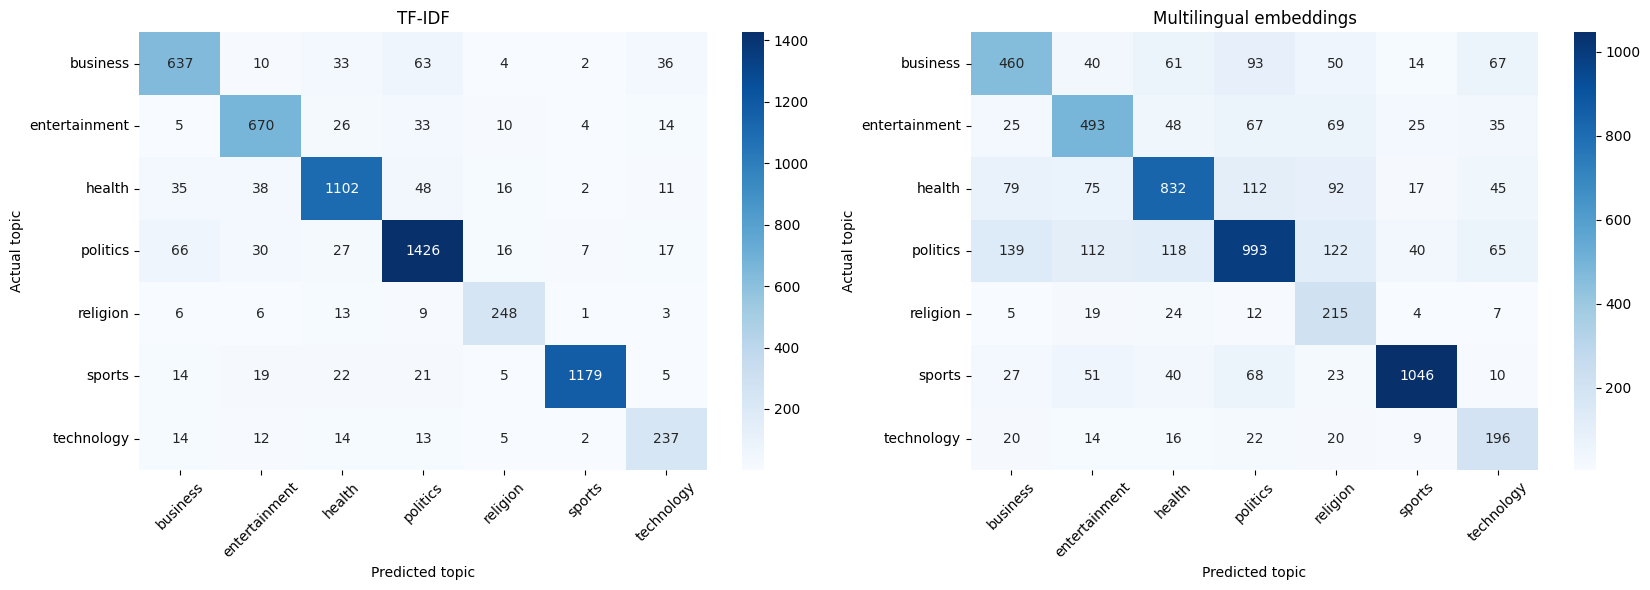

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, pred, title in [
    (axes[0], tfidf_test_pred, "TF-IDF"),
    (axes[1], embedding_test_pred, "Multilingual embeddings")
]:
    cm = confusion_matrix(y_test, pred, labels=np.arange(len(label_names)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=label_names, yticklabels=label_names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted topic")
    ax.set_ylabel("Actual topic")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

## 11. Performance by language

An overall score can hide differences between languages. We calculate accuracy and macro-F1 separately for each language using the same held-out test predictions.

In [18]:
language_results = []
test_languages = test_df["language"].to_numpy()

for lang_code, lang_name in LANGUAGES.items():
    mask = test_languages == lang_code
    if mask.sum() == 0:
        continue
    y_lang = y_test[mask]
    for model_name, pred in [
        ("TF-IDF", tfidf_test_pred),
        ("Multilingual embeddings", embedding_test_pred)
    ]:
        pred_lang = pred[mask]
        language_results.append({
            "language_code": lang_code,
            "language": lang_name,
            "model": model_name,
            "test_articles": int(mask.sum()),
            "accuracy": accuracy_score(y_lang, pred_lang),
            "macro_f1": f1_score(y_lang, pred_lang, average="macro", zero_division=0)
        })

language_results_df = pd.DataFrame(language_results)
display(language_results_df.round(3))

,language_code,language,model,test_articles,accuracy,macro_f1
0,amh,Amharic,TF-IDF,373,0.917,0.916
1,amh,Amharic,Multilingual embeddings,373,0.780,0.630
2,eng,English,TF-IDF,948,0.900,0.896
3,eng,English,Multilingual embeddings,948,0.844,0.720
4,fra,French,TF-IDF,422,0.870,0.847
5,fra,French,Multilingual embeddings,422,0.803,0.558
6,hau,Hausa,TF-IDF,637,0.878,0.866
7,hau,Hausa,Multilingual embeddings,637,0.551,0.529
8,ibo,Igbo,TF-IDF,387,0.837,0.829
9,ibo,Igbo,Multilingual embeddings,387,0.672,0.556


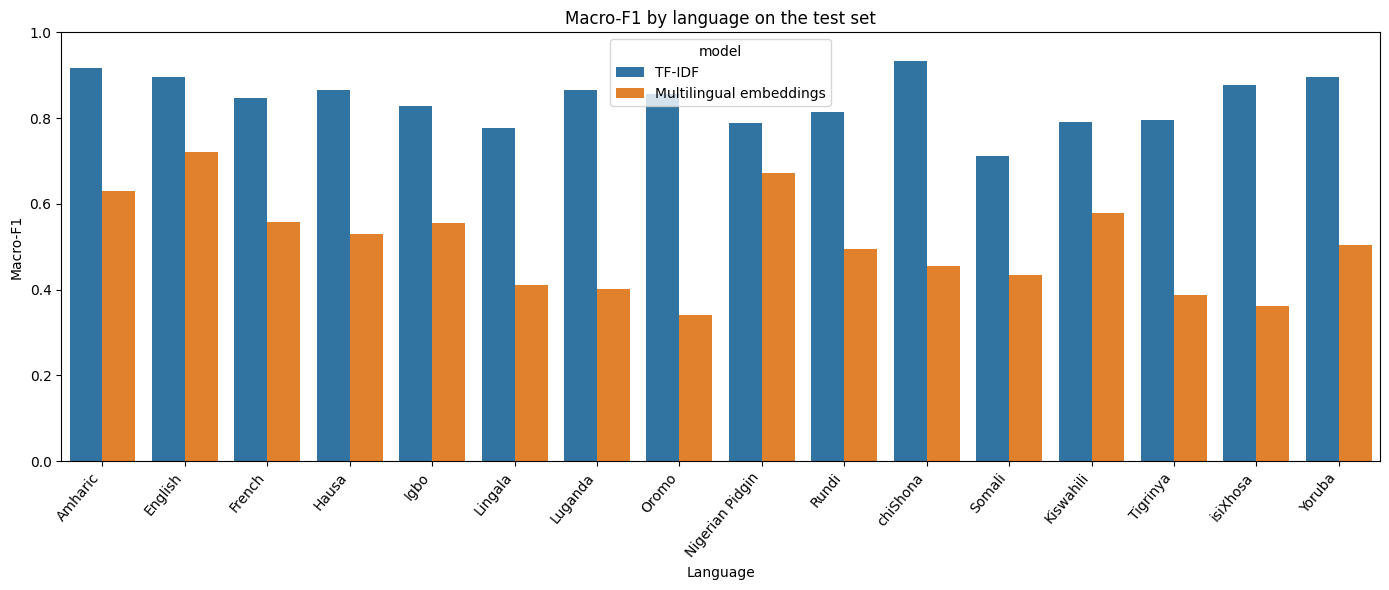

In [19]:
plt.figure(figsize=(14, 6))
sns.barplot(data=language_results_df, x="language", y="macro_f1", hue="model")
plt.title("Macro-F1 by language on the test set")
plt.xlabel("Language")
plt.ylabel("Macro-F1")
plt.xticks(rotation=50, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 12. Inspect some incorrect predictions

Reviewing errors helps us understand the limits of the system. These examples are from the held-out test set.

In [20]:
error_df = pd.DataFrame({
    "text": X_test,
    "language": test_languages,
    "actual": label_encoder.inverse_transform(y_test),
    "tfidf_prediction": label_encoder.inverse_transform(tfidf_test_pred),
    "embedding_prediction": label_encoder.inverse_transform(embedding_test_pred)
})
error_df = error_df[
    (error_df["actual"] != error_df["tfidf_prediction"]) |
    (error_df["actual"] != error_df["embedding_prediction"])
].copy()

display(error_df.head(10))

,text,language,actual,tfidf_prediction,embedding_prediction
0,የናይጄሪያ ፖሊስ በሩዝ ፋብሪካ ተቆልፎባቸው እንዲሰሩ የተገደዱ 300 ሰራ...,amh,business,health,business
1,ኢትዮጵያ፡ በደረሰው የጎርፍ አደጋ 130 ሺህ ነዋሪዎች ተፈናቅለዋል በኢት...,amh,business,business,politics
4,ዓለም አቀፉ የገንዘብ ዝውውር ሥርዓት ስዊፍት ምንድን ነው? ስዊፍት የአገ...,amh,business,business,technology
5,የሳምሰንግ ትርፍ ከ50 በመቶ በላይ አሽቆለቆለ የኤሌክትሮኒክስ ምርቶች አ...,amh,business,business,technology
12,"""ለ15 ዓመታት ኮንዶሚኒየም እየጠበቅኩ ሁለት ልጆች ወልጃለሁ"" የአዲስ አ...",amh,business,business,health
13,ፈረንሳዊው ቢሊየነር በፓሪስ ተደብድበው ተዘረፉ የፈረንሳዩ ቢሊየነር በርና...,amh,business,business,politics
15,"""በደቡብ አፍሪካ ኢትዮጵያውያን ነጋዴዎች ፈርተው ዛሬ መደብር አልከፈቱም""...",amh,business,politics,business
18,እሷ ማናት? #4፡ ከሒሳብ ጋር በአጋጣሚ ነው የተዋደድነው በሒሳብ ትምህር...,amh,business,health,health
21,ፓኪስታን ፡ በካርቱን ስዕል ምክንያት የፈረንሣይ ምርቶችን መጠቀም ልታቆም...,amh,business,politics,politics
24,ከኮሮናቫይረስ በኋላ ኢኮኖሚያቸው በቶሎ ሊያገግም የሚችል አምስት አገራት ...,amh,business,business,health


## 13. Save trained models, metadata and measured results

This cell saves all required artifacts into `/content/african_news_classifier`. The sentence-transformer encoder itself is downloaded by name when the app starts, while the trained Logistic Regression classifier is saved locally.

In [21]:
# Save the fitted estimators.
joblib.dump(tfidf_model, MODEL_DIR / "tfidf_model.joblib")
joblib.dump(embedding_model, MODEL_DIR / "embedding_classifier.joblib")

metadata = {
    "dataset": "masakhane/masakhanews",
    "languages": LANGUAGES,
    "topics": label_names,
    "embedding_model": EMBEDDING_MODEL_NAME,
    "train_size": int(len(train_df)),
    "validation_size": int(len(val_df)),
    "test_size": int(len(test_df))
}
(MODEL_DIR / "metadata.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8"
)

metrics_json = {
    "comparison": comparison.to_dict(orient="records"),
    "language_results": language_results_df.to_dict(orient="records"),
    "tfidf_classification_report": classification_report(
        y_test, tfidf_test_pred, target_names=label_names,
        output_dict=True, zero_division=0
    ),
    "embedding_classification_report": classification_report(
        y_test, embedding_test_pred, target_names=label_names,
        output_dict=True, zero_division=0
    )
}
(MODEL_DIR / "metrics.json").write_text(
    json.dumps(metrics_json, indent=2), encoding="utf-8"
)

error_df.to_csv(PROJECT_DIR / "test_errors.csv", index=False)
language_results_df.to_csv(PROJECT_DIR / "language_results.csv", index=False)
comparison.to_csv(PROJECT_DIR / "model_comparison.csv", index=False)

# Keep the dataset out of the repository/package; it is downloaded from Hugging Face.
print("Saved model files:")
for p in MODEL_DIR.iterdir():
    print(p.name, f"{p.stat().st_size / (1024**2):.1f} MB")

Saved model files:
embedding_classifier.joblib 0.0 MB
metadata.json 0.0 MB
tfidf_model.joblib 26.7 MB
metrics.json 0.0 MB


## 14. Create the Gradio web application

This cell writes `app.py`. The app lets a user paste an article and choose either trained model. The embedding model is loaded from Hugging Face when the app starts.

In [28]:
app_code = r"""
import json
from pathlib import Path
import joblib
import gradio as gr
import numpy as np
from sentence_transformers import SentenceTransformer

BASE = Path(__file__).parent
MODEL_DIR = BASE / "models"
metadata = json.loads((MODEL_DIR / "metadata.json").read_text(encoding="utf-8"))
labels = metadata["topics"]

tfidf_model = joblib.load(MODEL_DIR / "tfidf_model.joblib")
embedding_classifier = joblib.load(MODEL_DIR / "embedding_classifier.joblib")
encoder = SentenceTransformer(metadata["embedding_model"])

def classify(article, model_choice):
    if not article or len(article.strip()) < 20:
        return {"Please enter a longer article (at least 20 characters).": 1.0}

    if model_choice == "TF-IDF + Logistic Regression":
        probs = tfidf_model.predict_proba([article])[0]
    else:
        vector = encoder.encode([article], normalize_embeddings=True)
        probs = embedding_classifier.predict_proba(vector)[0]

    return {labels[i]: float(probs[i]) for i in np.argsort(probs)[::-1]}

with gr.Blocks(title="African News Classifier", theme=gr.themes.Soft()) as demo:
    gr.Markdown("# African News Classifier")
    gr.Markdown(
        "Paste a news article to predict its topic. The models were trained "
        "on MasakhaNEWS data from 16 language configurations."
    )
    gr.Markdown("**Topics:** " + ", ".join(labels))
    article = gr.Textbox(
        label="News article",
        lines=10,
        placeholder="Paste the headline and article text..."
    )
    model_choice = gr.Radio(
        ["TF-IDF + Logistic Regression",
         "Multilingual embeddings + Logistic Regression"],
        value="Multilingual embeddings + Logistic Regression",
        label="Choose model"
    )
    button = gr.Button("Classify article", variant="primary")
    output = gr.Label(label="Predicted topic probabilities", num_top_classes=7)
    button.click(classify, inputs=[article, model_choice], outputs=output)
    gr.Markdown(
        "**Limitations:** Model scores are estimates, not verified facts. "
        "Performance may vary by language, topic and source."
    )

if __name__ == "__main__":
    demo.launch(share=True)
"""
(PROJECT_DIR / "app.py").write_text(app_code, encoding="utf-8")
print("Created:", PROJECT_DIR / "app.py")

Created: /content/african_news_classifier/app.py


## 15. Create requirements and project README

These files document how to run the application outside Colab and what the project does.

In [29]:
requirements_text = """
datasets>=2.18
pandas>=2.0
numpy>=1.24
scikit-learn>=1.3
sentence-transformers>=2.6
torch>=2.1
joblib>=1.3
gradio>=4.0
"""

readme_text = f"""
# African News Classifier

NLP capstone project classifying African news articles into seven topics using the MasakhaNEWS dataset.

## Dataset
- Source: https://huggingface.co/datasets/masakhane/masakhanews
- 16 language configurations
- Topics: {", ".join(label_names)}
- Official train, validation and test splits
- Review the dataset card and licence before redistribution or commercial use.

## Models
1. TF-IDF word and character n-grams + Logistic Regression
2. Multilingual sentence embeddings (`{EMBEDDING_MODEL_NAME}`) + Logistic Regression

## Measured test results
See `models/metrics.json` and `model_comparison.csv`. These values were generated by running the notebook and must not be replaced with invented scores.

## Run locally
```bash
pip install -r requirements.txt
python app.py
```

The trained model files in `models/` must be present. The sentence-transformer encoder is downloaded by name on first launch.

## Limitations
- Performance can differ considerably between languages.
- The dataset may not represent every news source, region or writing style.
- Predictions are not fact-checking and should be reviewed by a human.
- This model should not be treated as a production editorial decision-maker without further testing.

## Team
Add the real team members and their contributions here.
"""
(PROJECT_DIR / "requirements.txt").write_text(requirements_text.strip() + "\n", encoding="utf-8")
(PROJECT_DIR / "README.md").write_text(readme_text.strip() + "\n", encoding="utf-8")
print("Created README.md and requirements.txt")

Created README.md and requirements.txt


## 16. Test the Gradio app inside Colab

This launches a temporary demo. Colab may display a public `gradio.live` link. Do not close the notebook while testing. For a permanent app, deploy the generated files to Hugging Face Spaces in the next step.

In [ ]:
%cd /content/african_news_classifier
!python app.py

/content/african_news_classifier
Loading weights: 100% 199/199 [00:00<00:00, 4391.32it/s]
/content/african_news_classifier/app.py:30: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="African News Classifier", theme=gr.themes.Soft()) as demo:
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://c35a8b7e42830d68f5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 17. Package the deliverables for download

Run this after training and after the `app.py`, `README.md` and `requirements.txt` files have been created. It creates a ZIP that you can download and later upload to GitHub or Hugging Face Spaces.

**Do not upload the dataset itself or any API keys.** This project does not require an API key.

In [31]:
%cd /content
zip_path = Path("/content/african_news_classifier_submission.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in PROJECT_DIR.rglob("*"):
        if path.is_file() and ".ipynb_checkpoints" not in str(path):
            zf.write(path, Path("african_news_classifier") / path.relative_to(PROJECT_DIR))

print("Created:", zip_path)
print(f"ZIP size: {zip_path.stat().st_size / (1024**2):.1f} MB")

from google.colab import files
files.download(str(zip_path))

/content
Created: /content/african_news_classifier_submission.zip
ZIP size: 20.7 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>